# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Abdul Wali
- **Student ID:** 023-24-0174
- **Section:** F
- **GitHub:** AWS9760
- **Kaggle:** *(enter your Kaggle profile link)*
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import glob
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score)

RANDOM_STATE = 42                      # same seed as Labs 3, 4 and 6
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = None


def evaluate(y_true, y_pred):
    """The four metrics used since Lab 3 (positive class = churn = 1)."""
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1-score": f1_score(y_true, y_pred)}


def find_file(names):
    """Look in the working folder, Colab's /content and Kaggle's /kaggle/input."""
    for name in names:
        for pattern in [name, f"/content/{name}", f"/content/**/{name}", f"/kaggle/input/**/{name}"]:
            hits = glob.glob(pattern, recursive=True)
            if hits:
                return hits[0]
    return None


raw_path = find_file(["WA_Fn-UseC_-Telco-Customer-Churn.csv", "WA_Fn-UseC_-Telco-Customer-Churn.xls"])
if raw_path is not None:
    df = pd.read_csv(raw_path)                      # the Kaggle file is a CSV (even when it is named .xls)
    print("Loaded raw Kaggle file:", raw_path, "| shape:", df.shape)

    # Lab 2 cleaning, re-applied step by step
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")       # 'blank' strings -> NaN
    missing = df["TotalCharges"].isna()
    print("TotalCharges missing after conversion:", int(missing.sum()),
          "| tenure of those customers:", sorted(df.loc[missing, "tenure"].unique()))
    df["TotalCharges"] = df["TotalCharges"].fillna(0)        # tenure 0 = brand-new customers, nothing billed yet
    df = df.drop(columns=["customerID"])                       # identifier, no predictive meaning
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})   # same as Lab 2 (Yes/No like the others)
else:
    clean_path = find_file(["clean_churn.csv"])               # the cleaned file saved in Lab 2
    if clean_path is None:
        raise FileNotFoundError("Upload the Telco churn CSV (or clean_churn.csv from Lab 2) to the Colab Files panel.")
    df = pd.read_csv(clean_path)
    print("Loaded the cleaned Lab 2 file:", clean_path)

print("Clean shape:", df.shape, "| missing values left:", int(df.isna().sum().sum()))

Loaded raw Kaggle file: WA_Fn-UseC_-Telco-Customer-Churn.xls | shape: (7043, 21)
TotalCharges missing after conversion: 11 | tenure of those customers: [np.int64(0)]
Clean shape: (7043, 20) | missing values left: 0


In [2]:
# One-hot encode, define X and y, train_test_split(..., stratify=y)
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True).astype(float)
print("Categorical columns encoded:", len(categorical_cols), "| X shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)          # identical split to Labs 3/4/6
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Churn rate  train: {y_train.mean():.1%}  test: {y_test.mean():.1%}")
print("\nValue ranges the SVM will see WITHOUT scaling:")
display(X_train[["tenure", "MonthlyCharges", "TotalCharges", "Contract_Two year"]].describe().loc[["mean", "std", "min", "max"]])

Categorical columns encoded: 16 | X shape: (7043, 30)
X_train: (5634, 30) | X_test: (1409, 30)
Churn rate  train: 26.5%  test: 26.5%

Value ranges the SVM will see WITHOUT scaling:


,tenure,MonthlyCharges,TotalCharges,Contract_Two year
mean,32.485,64.930,"2,299.335",0.241
std,24.569,30.138,"2,279.204",0.428
min,0.000,18.400,0.000,0.000
max,72.000,118.750,"8,684.800",1.000


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# YOUR CODE HERE — unscaled linear SVM
# Without a cap the libsvm solver did not finish in a reasonable time on these features (see Answer a),
# so the run is capped at 1,000,000 iterations and any warning is recorded.
MAX_ITER = 1_000_000

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    start = time.time()
    svm_raw = SVC(kernel="linear", random_state=42, max_iter=MAX_ITER)
    svm_raw.fit(X_train, y_train)
    time_raw = time.time() - start
warnings_raw = [str(w.message) for w in caught if "terminated early" in str(w.message) or "converge" in str(w.message).lower()]

pred_raw = svm_raw.predict(X_test)
metrics_raw = evaluate(y_test, pred_raw)
print(f"Training time: {time_raw:.1f} s | solver iterations: {int(svm_raw.n_iter_[0]):,} | support vectors: {svm_raw.support_.shape[0]}")
print("Warnings:", warnings_raw if warnings_raw else "none")
print({k: round(v, 4) for k, v in metrics_raw.items()})

Training time: 18.8 s | solver iterations: 1,000,000 | support vectors: 1166
Warnings: ['Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.']
{'Accuracy': 0.5926, 'Precision': 0.358, 'Recall': 0.6738, 'F1-score': 0.4675}


In [4]:
# YOUR CODE HERE — scaled linear SVM
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)        # fit on TRAIN only
X_test_s = scaler.transform(X_test)              # TEST is only transformed with the train mean/std

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    start = time.time()
    svm_lin = SVC(kernel="linear", random_state=42)          # no iteration cap needed
    svm_lin.fit(X_train_s, y_train)
    time_lin = time.time() - start
warnings_lin = [str(w.message) for w in caught if "terminated early" in str(w.message) or "converge" in str(w.message).lower()]
pred_lin = svm_lin.predict(X_test_s)
metrics_lin = evaluate(y_test, pred_lin)

scaling_table = pd.DataFrame([
    {"Features": "un-scaled", **metrics_raw, "Train time (s)": time_raw, "Solver iterations": int(svm_raw.n_iter_[0]),
     "Support vectors": svm_raw.support_.shape[0], "Converged": not warnings_raw},
    {"Features": "StandardScaler", **metrics_lin, "Train time (s)": time_lin, "Solver iterations": int(svm_lin.n_iter_[0]),
     "Support vectors": svm_lin.support_.shape[0], "Converged": not warnings_lin},
]).set_index("Features")
display(scaling_table)
print("Unscaled run predicted churn for", int(pred_raw.sum()), "test customers vs", int(pred_lin.sum()), "for the scaled run (actual churners:", int(y_test.sum()), ")")

,Accuracy,Precision,Recall,F1-score,Train time (s),Solver iterations,Support vectors,Converged
Features,,,,,,,,
un-scaled,0.593,0.358,0.674,0.468,18.792,1000000,1166,False
StandardScaler,0.789,0.619,0.527,0.569,0.991,73860,2567,True


Unscaled run predicted churn for 704 test customers vs 318 for the scaled run (actual churners: 374 )


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The difference is dramatic. The unscaled SVM never converged: libsvm stopped at my cap of 1,000,000 iterations with the warning *"Solver terminated early ... Consider pre-processing your data with StandardScaler"* after 18.8 s (when I ran it once without a cap it needed about 8 minutes to finish). The scaled SVM converged by itself in 73,860 iterations and 1.0 s. The half-trained unscaled model is also much worse: accuracy 0.593 vs 0.789 and F1 0.468 vs 0.569. It flagged 704 test customers as churners (there are only 374), so its precision collapsed to 0.358; its accuracy is even below the 0.735 of always predicting "no churn".

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* The margin is a geometric distance, 2/‖w‖, and the SVM minimises ‖w‖² while keeping points outside it. Without scaling, `TotalCharges` ranges from 0 to about 8,700 (std ≈ 2,279) while the one-hot columns are 0/1 (std below 0.5), so distances between customers are almost entirely distances in `TotalCharges`. The penalty on ‖w‖ treats every weight equally, so a 0/1 feature needs a weight thousands of times larger than `TotalCharges` to have the same effect. That makes the optimisation problem badly conditioned: the solver moves in tiny, unbalanced steps, needs an enormous number of iterations, and stops far from the optimum.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* The scaled version (`StandardScaler` fitted on the training set only, then applied to the test set) for every SVM, and also for the PCA in Part 3. Scaled features gave a converged, faster and more accurate model. Fitting the scaler on the training data only keeps test information out of the model, the same leakage rule as in Labs 4–6.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernel_models, kernel_rows = {}, []
for kernel in ["linear", "rbf", "poly"]:
    start = time.time()
    model = SVC(kernel=kernel, random_state=42).fit(X_train_s, y_train)      # default C=1, gamma='scale', degree=3
    fit_time = time.time() - start
    kernel_models[kernel] = model
    pred = model.predict(X_test_s)
    kernel_rows.append({"Kernel": kernel, **evaluate(y_test, pred),
                        "Support vectors": model.support_.shape[0],
                        "SV per class (no churn / churn)": f"{model.n_support_[0]} / {model.n_support_[1]}",
                        "Train time (s)": fit_time})
    print(f"{kernel:<6} trained in {fit_time:.1f} s")

linear trained in 0.9 s
rbf    trained in 0.6 s
poly   trained in 0.5 s


In [6]:
# YOUR CODE HERE — comparison table
kernel_table = pd.DataFrame(kernel_rows).set_index("Kernel")
kernel_table["SV share of train set"] = kernel_table["Support vectors"] / len(X_train_s)
display(kernel_table)
best_kernel = kernel_table["F1-score"].idxmax()
print("Best kernel on test F1:", best_kernel)

# One test split can be noisy -> same comparison with 5-fold CV on the TRAINING data
cv_rows = []
for kernel in ["linear", "rbf", "poly"]:
    res = cross_validate(SVC(kernel=kernel, random_state=42), X_train_s, y_train, cv=5, scoring=["f1", "recall"])
    cv_rows.append({"Kernel": kernel, "CV F1 (mean)": res["test_f1"].mean(), "CV F1 (std)": res["test_f1"].std(),
                    "CV recall (mean)": res["test_recall"].mean()})
kernel_cv = pd.DataFrame(cv_rows).set_index("Kernel")
display(kernel_cv)

,Accuracy,Precision,Recall,F1-score,Support vectors,SV per class (no churn / churn),Train time (s),SV share of train set
Kernel,,,,,,,,
linear,0.789,0.619,0.527,0.569,2567,1286 / 1281,0.910,0.456
rbf,0.793,0.644,0.489,0.556,2657,1428 / 1229,0.597,0.472
poly,0.789,0.642,0.465,0.540,2736,1482 / 1254,0.524,0.486


Best kernel on test F1: linear


,CV F1 (mean),CV F1 (std),CV recall (mean)
Kernel,,,
linear,0.582,0.027,0.530
rbf,0.577,0.029,0.504
poly,0.560,0.033,0.475


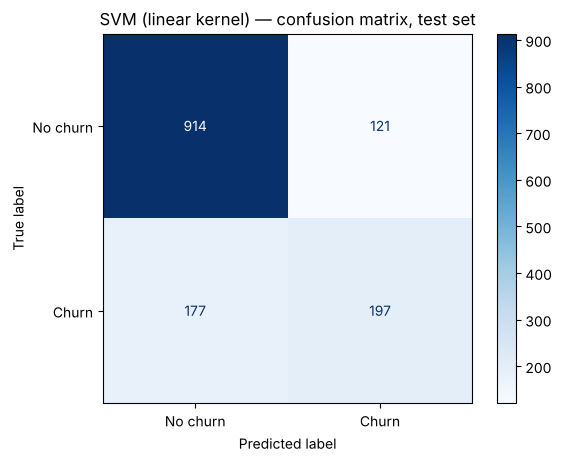

TN=914  FP=121  FN=177  TP=197  -> 177 of 374 churners are missed


In [7]:
# YOUR CODE HERE — confusion matrix for the best kernel
cm_best_kernel = confusion_matrix(y_test, kernel_models[best_kernel].predict(X_test_s))
ConfusionMatrixDisplay(cm_best_kernel, display_labels=["No churn", "Churn"]).plot(cmap="Blues", values_format="d")
plt.title(f"SVM ({best_kernel} kernel) — confusion matrix, test set")
plt.show()
tn_k, fp_k, fn_k, tp_k = cm_best_kernel.ravel()
print(f"TN={tn_k}  FP={fp_k}  FN={fn_k}  TP={tp_k}  -> {fn_k} of {fn_k + tp_k} churners are missed")

**Observation (confusion matrix, linear kernel):** TN = 914, FP = 121, FN = 177, TP = 197. The default SVM is conservative: it is right about most loyal customers, but it misses 177 of the 374 churners (recall 0.527), which is the weakness Part 5 targets.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The **linear** kernel: F1 0.569, against 0.556 for RBF and 0.540 for polynomial. The 5-fold CV on the training set gives the same order (0.582 / 0.577 / 0.560), although linear and RBF are well within one fold standard deviation (about 0.03) of each other. It does not really surprise me. In theory RBF is the more flexible kernel, but flexibility only helps if the boundary is curved. Here 27 of the 30 features are 0/1 dummies, Logistic Regression (also linear) was my best model in Lab 6, and the RBF and polynomial kernels were run with untuned defaults (C = 1, gamma = 'scale', degree 3).

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* **Polynomial**, with 2,736 support vectors (48.6% of the training set), then RBF with 2,657 and linear with 2,567. Every support vector is a point on or inside the margin that shapes the boundary, so a high count means a less sparse and usually more complex boundary that depends on many individual customers. Here all three kernels use almost half of the training set, so the main message is that churners and non-churners overlap heavily and no kernel separates them cleanly. The polynomial kernel needs the most points and still scores the lowest F1 and recall (0.465), so its extra complexity buys nothing.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* **RBF**. Its default F1 (0.556 test, 0.577 CV) is only 0.013 / 0.005 behind linear, much less than the fold-to-fold spread. It also has two knobs (C and gamma) that can move it anywhere from an almost linear boundary (small gamma) to a very local one. The polynomial kernel is the worst on F1 and recall and uses the most support vectors, so it is dropped. The linear SVM (test F1 0.569) stays as the benchmark the tuned RBF has to beat.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)        # fitted on the SCALED TRAINING features only
X_test_2d = pca.transform(X_test_s)
evr = pca.explained_variance_ratio_
print(f"Explained variance ratio: PC1 = {evr[0]:.3f}, PC2 = {evr[1]:.3f}, total = {evr.sum():.3f}")

Explained variance ratio: PC1 = 0.332, PC2 = 0.120, total = 0.452


In [9]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_VALUES = [0.01, 1, 1000]                       # spans five orders of magnitude
svm_2d, rows_2d = {}, []
for C in C_VALUES:
    start = time.time()
    m = SVC(kernel="rbf", C=C, random_state=42).fit(X_train_2d, y_train)
    svm_2d[C] = m
    train_pred = m.predict(X_train_2d)
    test_pred = m.predict(X_test_2d)
    rows_2d.append({"C": C, "Support vectors": m.support_.shape[0],
                    "SV share of train set": m.support_.shape[0] / len(X_train_2d),
                    "Train accuracy": accuracy_score(y_train, train_pred), "Test accuracy": accuracy_score(y_test, test_pred),
                    "Train F1": f1_score(y_train, train_pred), "Test F1": f1_score(y_test, test_pred),
                    "Predicted churn share (train)": train_pred.mean(), "Fit time (s)": time.time() - start})
table_2d = pd.DataFrame(rows_2d).set_index("C")
display(table_2d)

,Support vectors,SV share of train set,Train accuracy,Test accuracy,Train F1,Test F1,Predicted churn share (train),Fit time (s)
C,,,,,,,,
0.010,2995,0.532,0.735,0.735,0.000,0.000,0.000,0.888
1.000,2658,0.472,0.779,0.779,0.481,0.477,0.160,0.939
"1,000.000",2604,0.462,0.781,0.779,0.494,0.485,0.167,8.155


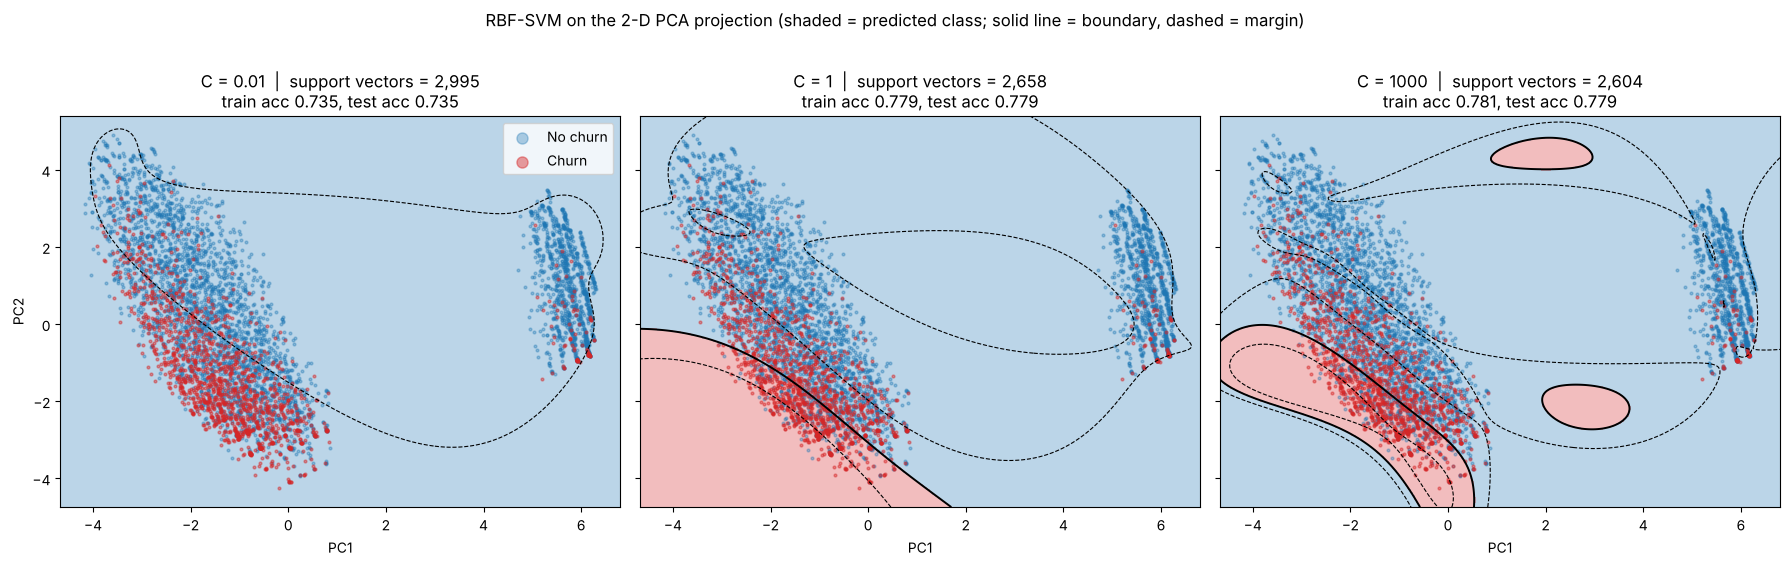

In [10]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
pad = 0.5
x_min, x_max = X_train_2d[:, 0].min() - pad, X_train_2d[:, 0].max() + pad
y_min, y_max = X_train_2d[:, 1].min() - pad, X_train_2d[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
for ax, C in zip(axes, C_VALUES):
    m = svm_2d[C]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(["tab:blue", "tab:red"]), levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, m.decision_function(grid).reshape(xx.shape), levels=[-1, 0, 1],
               colors="k", linestyles=["--", "-", "--"], linewidths=[0.8, 1.4, 0.8])
    ax.scatter(X_train_2d[y_train.values == 0, 0], X_train_2d[y_train.values == 0, 1], s=4, c="tab:blue", alpha=0.35, label="No churn")
    ax.scatter(X_train_2d[y_train.values == 1, 0], X_train_2d[y_train.values == 1, 1], s=4, c="tab:red", alpha=0.45, label="Churn")
    ax.set_title(f"C = {C}  |  support vectors = {m.support_.shape[0]:,}\n"
                 f"train acc {table_2d.loc[C, 'Train accuracy']:.3f}, test acc {table_2d.loc[C, 'Test accuracy']:.3f}")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(loc="upper right", markerscale=4)
fig.suptitle("RBF-SVM on the 2-D PCA projection (shaded = predicted class; solid line = boundary, dashed = margin)", y=1.02)
plt.tight_layout()
plt.show()

*PCA result:* the two components explain 33.2% + 12.0% = **45.2%** of the variance of the scaled training features, so the plots show less than half of the information the real model uses.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At **C = 0.01** there is no churn region at all: the whole plane is predicted "no churn" and the dashed margin is a huge loop around almost all the data. At **C = 1** a single, smooth curved boundary cuts off the lower-left part of the main cluster, where most churners lie. At **C = 1000** the boundary hugs the churn area more tightly, bends around local groups of points, and creates small isolated churn "islands" in almost empty regions (around PC1 ≈ 2.5). As C grows, the boundary goes from absent, to smooth, to wiggly and fragmented.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* It falls from 2,995 (C = 0.01) to 2,658 (C = 1) to 2,604 (C = 1000). This matches the theory: a larger C punishes margin violations more, so the margin narrows and fewer points lie on or inside it. The drop is small (from 53% to 46% of the training set) because the two classes overlap so much in 2-D that even a very large C cannot push most points outside the margin.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* **C = 0.01 underfits.** It predicts nobody as a churner (train F1 0.000), and its accuracy of 0.735 is just the share of non-churners: the margin is so wide that the model gives up on the minority class. **C = 1000 overfits.** It draws isolated churn islands where there are hardly any training points and bends the boundary around small local groups, i.e. it follows noise. The numbers show how little that buys: train accuracy 0.781 vs 0.779 for C = 1, test accuracy 0.779 vs 0.779, and the fit took 9 times longer. C = 1 gives the most sensible picture: one smooth boundary through the region where the classes meet.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The real SVM works in 30 dimensions (and the RBF kernel implicitly in an even richer feature space), while the plot keeps only 45% of the variance. PCA chooses the directions of largest variance, not the directions that separate churners best, so customers that overlap in the plot may be separable in the full space (the full RBF model in Part 2 reached test F1 0.556 against 0.477 in 2-D). The plot can therefore exaggerate how much the classes overlap, show a boundary shape that does not exist in 30-D, and suggest support-vector counts and C effects that differ from the real model. Gamma also means something different, because 'scale' depends on the number and variance of the features.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]}
start = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)                     # scaled TRAINING data only
grid_time = time.time() - start
best_C, best_gamma = gs.best_params_["C"], gs.best_params_["gamma"]
print(f"{len(gs.cv_results_['params'])} combinations x 5 folds = {5 * len(gs.cv_results_['params'])} fits in {grid_time:.0f} s")
print("Best parameters:", gs.best_params_, f"| best mean CV F1 = {gs.best_score_:.4f}")

16 combinations x 5 folds = 80 fits in 37 s
Best parameters: {'C': 100, 'gamma': 0.01} | best mean CV F1 = 0.5876


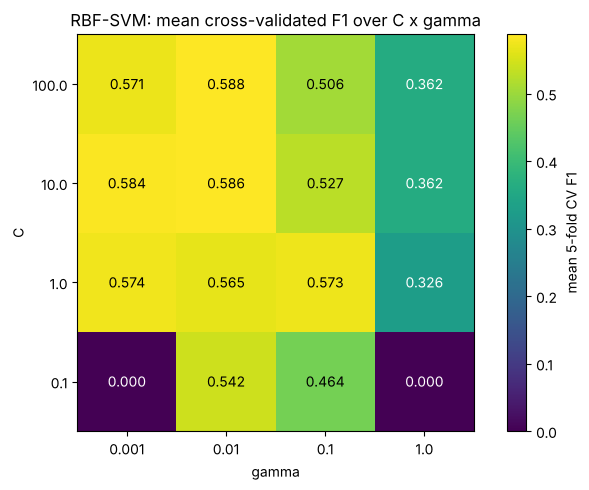

Mean CV F1 (rows = C, columns = gamma):


param_gamma,0.001,0.01,0.1,1.0
param_C,,,,
0.100,0.000,0.542,0.464,0.000
1.000,0.574,0.565,0.573,0.326
10.000,0.584,0.586,0.527,0.362
100.000,0.571,0.588,0.506,0.362


Std of CV F1 across folds:


param_gamma,0.001,0.01,0.1,1.0
param_C,,,,
0.100,0.000,0.032,0.037,0.000
1.000,0.023,0.034,0.027,0.026
10.000,0.033,0.027,0.021,0.025
100.000,0.031,0.022,0.022,0.024


,param_C,param_gamma,mean_test_score,std_test_score
0,100.000,0.010,0.588,0.022
1,10.000,0.010,0.586,0.027
2,10.000,0.001,0.584,0.033
3,1.000,0.001,0.574,0.023
4,1.000,0.100,0.573,0.027


In [12]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
cv_res = pd.DataFrame(gs.cv_results_)
heat = cv_res.pivot(index="param_C", columns="param_gamma", values="mean_test_score")
heat_std = cv_res.pivot(index="param_C", columns="param_gamma", values="std_test_score")

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat.values, cmap="viridis", origin="lower")
ax.set_xticks(range(len(heat.columns)), [str(g) for g in heat.columns])
ax.set_yticks(range(len(heat.index)), [str(c) for c in heat.index])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v < 0.45 else "black", fontsize=10)
plt.colorbar(im, label="mean 5-fold CV F1")
ax.set_title("RBF-SVM: mean cross-validated F1 over C x gamma")
plt.tight_layout()
plt.show()

print("Mean CV F1 (rows = C, columns = gamma):")
display(heat)
print("Std of CV F1 across folds:")
display(heat_std)
top5 = cv_res.sort_values("mean_test_score", ascending=False)[["param_C", "param_gamma", "mean_test_score", "std_test_score"]].head(5)
display(top5.reset_index(drop=True))

,Accuracy,Precision,Recall,F1-score,Support vectors
"RBF default (C=1, gamma='scale') - Part 2",0.793,0.644,0.489,0.556,2657
"RBF tuned (C=100, gamma=0.01)",0.779,0.594,0.524,0.557,2599


CV F1 of the tuned model: 0.5876  vs  its test F1: 0.5568
gamma='scale' equals 0.0333 here; default RBF mean CV F1 = 0.5770


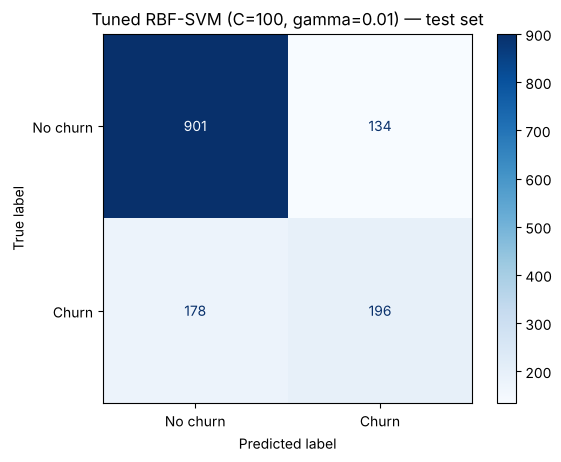

In [13]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
svm_tuned = gs.best_estimator_                 # GridSearchCV already refit it on the whole training set (refit=True)
pred_tuned = svm_tuned.predict(X_test_s)
pred_rbf_default = kernel_models["rbf"].predict(X_test_s)

tuning_table = pd.DataFrame(
    [evaluate(y_test, pred_rbf_default), evaluate(y_test, pred_tuned)],
    index=["RBF default (C=1, gamma='scale') - Part 2", f"RBF tuned (C={best_C}, gamma={best_gamma})"])
tuning_table["Support vectors"] = [kernel_models["rbf"].support_.shape[0], svm_tuned.support_.shape[0]]
display(tuning_table)
print(f"CV F1 of the tuned model: {gs.best_score_:.4f}  vs  its test F1: {f1_score(y_test, pred_tuned):.4f}")
default_gamma = 1 / (X_train_s.shape[1] * X_train_s.var())
default_cv = cross_validate(SVC(kernel="rbf", random_state=42), X_train_s, y_train, cv=5, scoring="f1")["test_score"]
print(f"gamma='scale' equals {default_gamma:.4f} here; default RBF mean CV F1 = {default_cv.mean():.4f}")

cm_tuned = confusion_matrix(y_test, pred_tuned)
ConfusionMatrixDisplay(cm_tuned, display_labels=["No churn", "Churn"]).plot(cmap="Blues", values_format="d")
plt.title(f"Tuned RBF-SVM (C={best_C}, gamma={best_gamma}) — test set")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* **C = 100, gamma = 0.01**, with a mean 5-fold CV F1 of **0.588** (std 0.022 across folds).

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* There is a broad plateau rather than a single peak. All cells with C ≥ 1 and gamma ≤ 0.01 (and C = 1 with gamma = 0.1) score between 0.565 and 0.588, and the top five combinations lie within 0.014 of each other. That is smaller than the fold-to-fold standard deviation (about 0.02–0.03), so the runner-up C = 10, gamma = 0.01 (0.586) is effectively as good as the winner. The clearly bad regions are gamma = 1 with C ≥ 1 (F1 of only 0.33–0.36: each support vector influences only a tiny neighbourhood, so the model memorises points) and C = 0.1 with gamma 0.001 or 1 (F1 = 0: the model predicts nobody churns, like C = 0.01 in Part 3). Inside the plateau the model is not sensitive to exact values; it only needs to avoid the extremes.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* There was a modest gap: CV F1 0.588 against test F1 0.557, a difference of 0.031, roughly one to one-and-a-half fold standard deviations. Part of it is expected optimism, because the reported CV score is the maximum of 16 noisy estimates; part is just which 1,409 customers ended up in the test set. A large gap would suggest that the hyperparameters had been overfitted to the CV folds (for example, a very fine grid on a small dataset), that the test set comes from a different distribution, or that information leaked into the CV (for example, a scaler fitted on all the data).

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* Barely. Test F1 went from 0.556 to 0.557: recall rose (0.489 → 0.524), but precision (0.644 → 0.594) and accuracy (0.793 → 0.779) fell. In CV the gain is 0.011 (0.577 → 0.588). The reason is that the default gamma = 'scale' equals 0.0333 here, which already sits inside the good plateau. The 80 fits (37 s) were worth it as evidence that the defaults are not a bad guess and to map the regions to avoid, but not for the F1 they added. Changing the class weights in Part 5 helped far more.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


'balanced' class weights: no churn = 0.681, churn = 1.884  (a churner's error costs 2.77x more)


,Accuracy,Precision,Recall,F1-score,TP,FN (missed churners),FP (loyal flagged),Customers flagged
class_weight=None,0.779,0.594,0.524,0.557,196,178,134,330
class_weight='balanced',0.747,0.516,0.770,0.618,288,86,270,558


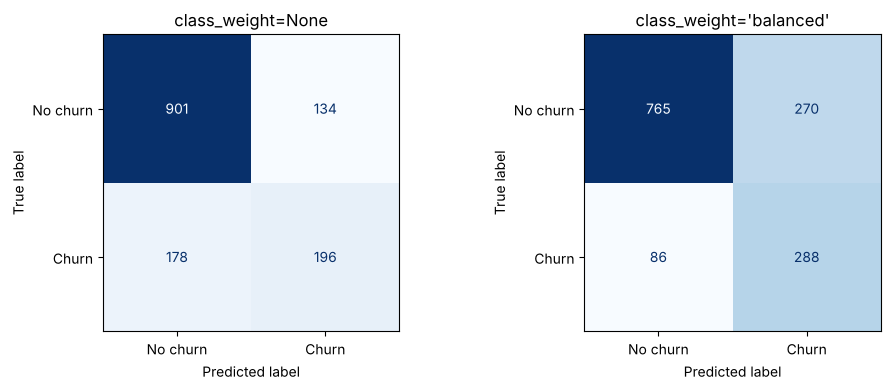

In [14]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
# probability=True makes SVC fit an extra Platt-scaling model (internal 5-fold CV) so predict_proba() exists.
svm_none = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None, probability=True, random_state=42).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced", probability=True, random_state=42).fit(X_train_s, y_train)
pred_none = svm_none.predict(X_test_s)
pred_bal = svm_bal.predict(X_test_s)

weights = len(y_train) / (2 * np.bincount(y_train))
print(f"'balanced' class weights: no churn = {weights[0]:.3f}, churn = {weights[1]:.3f}  (a churner's error costs {weights[1] / weights[0]:.2f}x more)")
imbalance_table = pd.DataFrame([evaluate(y_test, pred_none), evaluate(y_test, pred_bal)],
                               index=["class_weight=None", "class_weight='balanced'"])
cm_none, cm_bal = confusion_matrix(y_test, pred_none), confusion_matrix(y_test, pred_bal)
imbalance_table["TP"] = [cm_none[1, 1], cm_bal[1, 1]]
imbalance_table["FN (missed churners)"] = [cm_none[1, 0], cm_bal[1, 0]]
imbalance_table["FP (loyal flagged)"] = [cm_none[0, 1], cm_bal[0, 1]]
imbalance_table["Customers flagged"] = [pred_none.sum(), pred_bal.sum()]
display(imbalance_table)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cm, title in [(axes[0], cm_none, "class_weight=None"), (axes[1], cm_bal, "class_weight='balanced'")]:
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

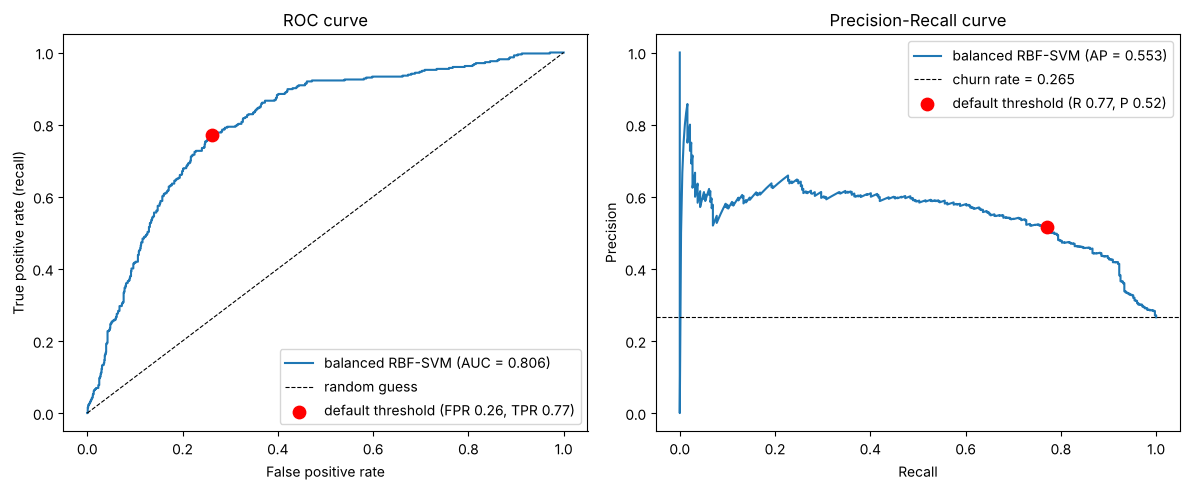

ROC AUC  balanced: 0.806 | class_weight=None: 0.788
ROC AUC using predict_proba instead of decision_function: 0.806
predict_proba >= 0.5 agrees with predict() for 85.2% of test customers


In [15]:
# YOUR CODE HERE — ROC or Precision-Recall curve
score_bal = svm_bal.decision_function(X_test_s)     # signed distance to the boundary; predict() uses score > 0
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]   # Platt-scaled "probability" of churn

fpr, tpr, _ = roc_curve(y_test, score_bal)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, score_bal)
auc_bal = roc_auc_score(y_test, score_bal)
ap_bal = average_precision_score(y_test, score_bal)
auc_none = roc_auc_score(y_test, svm_none.decision_function(X_test_s))

# operating point of the default rule (decision_function > 0  <=>  what predict() returns)
op_fpr = cm_bal[0, 1] / cm_bal[0].sum()
op_tpr = cm_bal[1, 1] / cm_bal[1].sum()
op_prec = precision_score(y_test, pred_bal)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"balanced RBF-SVM (AUC = {auc_bal:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8, label="random guess")
axes[0].scatter(op_fpr, op_tpr, s=80, c="red", zorder=3, label=f"default threshold (FPR {op_fpr:.2f}, TPR {op_tpr:.2f})")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right")
axes[1].plot(rec_curve, prec_curve, label=f"balanced RBF-SVM (AP = {ap_bal:.3f})")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=0.8, label=f"churn rate = {y_test.mean():.3f}")
axes[1].scatter(op_tpr, op_prec, s=80, c="red", zorder=3, label=f"default threshold (R {op_tpr:.2f}, P {op_prec:.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"ROC AUC  balanced: {auc_bal:.3f} | class_weight=None: {auc_none:.3f}")
print(f"ROC AUC using predict_proba instead of decision_function: {roc_auc_score(y_test, proba_bal):.3f}")
agree = ((proba_bal >= 0.5).astype(int) == pred_bal).mean()
print(f"predict_proba >= 0.5 agrees with predict() for {agree:.1%} of test customers")

**Observation (ROC and PR curves):** The balanced model ranks churners well above chance (ROC AUC 0.806, average precision 0.553 against a baseline of 0.265). The red point is where the default rule (decision score > 0, i.e. `predict()`) operates: recall 0.77 at a false-positive rate of 0.26 and precision 0.52. Left of that point, the PR curve is quite flat around 0.55–0.6, so a stricter threshold would gain only a little precision for a large loss of recall. To the right of it, precision falls quickly. The unweighted model's AUC is 0.788, so the weights changed the ranking only slightly; their main effect is moving the operating point.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Precision fell from **0.594 to 0.516** (−0.078) and recall rose from **0.524 to 0.770** (+0.246), so F1 improved from 0.557 to 0.618, while accuracy dropped from 0.779 to 0.747. In customers: caught churners went from 196 to 288 (+92), missed churners from 178 to 86, and loyal customers wrongly flagged from 134 to 270 (+136). The weighting made each churner's error cost 2.77 times more during training.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* Missing a churner is more costly. A churner who is not contacted takes all future monthly revenue with them (the average monthly charge is about 65 per customer), and winning a new customer usually costs more than keeping an existing one. A false positive only costs a retention call or a discount for someone who would have stayed anyway. The balanced model catches 92 extra churners for 136 extra false alarms, about 1.5 false alarms per extra churner saved. That is a good trade unless the retention offer costs a large share of a customer's value. I would deploy the **`class_weight='balanced'`** model.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I set **`probability=True`**. `SVC` then fits an extra Platt-scaling model (a logistic function on the SVM's decision scores, learned with an internal 5-fold CV), which makes training slower and gives `predict_proba()`. For the curves I used `decision_function()`, the signed distance to the boundary, which is a natural ranking score for an SVM. It gives the same AUC (0.806), and its threshold of 0 is exactly what `predict()` uses. Platt probabilities ≥ 0.5 agree with `predict()` for only 85.2% of the test customers, so "0.5" is not exactly the SVM's default threshold. (In the newest scikit-learn, `probability=True` is deprecated in favour of `CalibratedClassifierCV`, but it still works.)


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [16]:
# YOUR CODE HERE — cross-model comparison table
# Earlier models re-run on this exact split with the settings chosen in Labs 3, 4 and 6.
final_models = {
    "Decision Tree (Lab 3, max_depth=6)": (DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), False),
    "Random Forest (Lab 4, tuned)": (RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=2,
                                                            random_state=RANDOM_STATE), False),
    "Logistic Regression (Lab 6)": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    "KNN (Lab 6, K=51)": (KNeighborsClassifier(n_neighbors=51), True),
    f"SVM (RBF, C={best_C}, gamma={best_gamma}, balanced)": (SVC(kernel="rbf", C=best_C, gamma=best_gamma,
                                                                 class_weight="balanced", random_state=42), True),
}
rows, preds_all = [], {}
for name, (model, needs_scaling) in final_models.items():
    Xtr, Xte = (X_train_s, X_test_s) if needs_scaling else (X_train, X_test)
    start = time.time()
    model.fit(Xtr, y_train)
    fit_time = time.time() - start
    preds_all[name] = model.predict(Xte)
    rows.append({"Model": name, **evaluate(y_test, preds_all[name]), "Train time (s)": fit_time})
showdown = pd.DataFrame(rows).set_index("Model")
display(showdown)
print("Best F1:", showdown["F1-score"].idxmax(), "| best recall:", showdown["Recall"].idxmax(),
      "| best precision:", showdown["Precision"].idxmax(), "| best accuracy:", showdown["Accuracy"].idxmax())

,Accuracy,Precision,Recall,F1-score,Train time (s)
Model,,,,,
"Decision Tree (Lab 3, max_depth=6)",0.801,0.667,0.497,0.570,0.016
"Random Forest (Lab 4, tuned)",0.805,0.662,0.540,0.595,0.803
Logistic Regression (Lab 6),0.807,0.658,0.567,0.609,0.017
"KNN (Lab 6, K=51)",0.786,0.596,0.599,0.597,0.001
"SVM (RBF, C=100, gamma=0.01, balanced)",0.747,0.516,0.770,0.618,2.191


Best F1: SVM (RBF, C=100, gamma=0.01, balanced) | best recall: SVM (RBF, C=100, gamma=0.01, balanced) | best precision: Decision Tree (Lab 3, max_depth=6) | best accuracy: Logistic Regression (Lab 6)


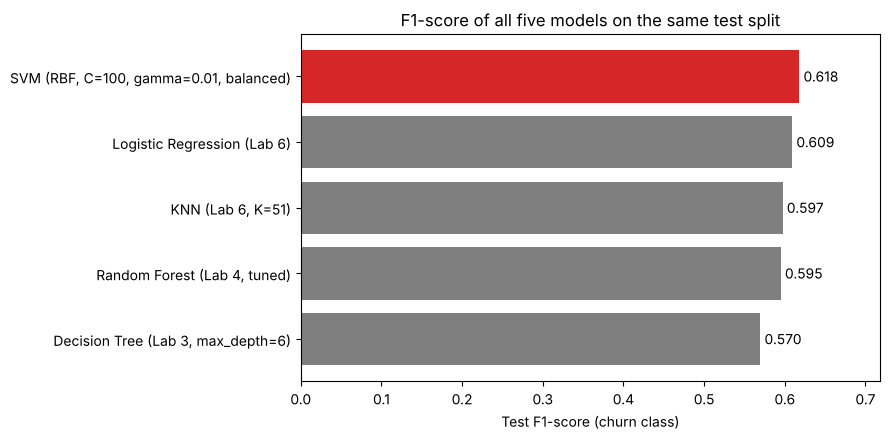

In [17]:
# YOUR CODE HERE — bar chart of F1-score across models
order = showdown["F1-score"].sort_values()
colors = ["tab:red" if name.startswith("SVM") else "tab:gray" for name in order.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(order.index, order.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlim(0, max(order.values) + 0.1)
ax.set_xlabel("Test F1-score (churn class)")
ax.set_title("F1-score of all five models on the same test split")
plt.tight_layout()
plt.show()

In [18]:
# Fairness check: is the SVM ahead because of the SVM itself, or because it is the only class-weighted model?
fair_rows = []
for name, model, scaled in [
        ("Logistic Regression, class_weight='balanced'", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE), True),
        ("Random Forest (tuned), class_weight='balanced'", RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=2,
                                                                                class_weight="balanced", random_state=RANDOM_STATE), False)]:
    Xtr, Xte = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    p = model.fit(Xtr, y_train).predict(Xte)
    fair_rows.append({"Model": name, **evaluate(y_test, p)})
fair_check = pd.concat([showdown.loc[[n for n in showdown.index if n.startswith("SVM")], ["Accuracy", "Precision", "Recall", "F1-score"]],
                        pd.DataFrame(fair_rows).set_index("Model")])
display(fair_check)

# One test split is noisy, so compare the class-weighted candidates with 5-fold CV on the TRAINING data
# (scaler inside the pipeline -> re-fitted in every fold, no leakage).
from sklearn.pipeline import make_pipeline
cv_candidates = {
    f"SVM RBF balanced (C={best_C}, gamma={best_gamma}) - grid winner": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced")),
    "SVM RBF balanced (C=10, gamma=0.01) - 2nd-best grid cell": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma=0.01, class_weight="balanced")),
    "Logistic Regression balanced": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest (tuned) balanced": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=2, class_weight="balanced", random_state=RANDOM_STATE),
}
rows = []
for name, model in cv_candidates.items():
    start = time.time()
    res = cross_validate(model, X_train, y_train, cv=5, scoring=["f1", "recall", "precision", "roc_auc"])
    rows.append({"Model": name, "CV F1": res["test_f1"].mean(), "F1 std": res["test_f1"].std(), "CV recall": res["test_recall"].mean(),
                 "CV precision": res["test_precision"].mean(), "CV ROC AUC": res["test_roc_auc"].mean(), "Time for 5 folds (s)": time.time() - start})
cv_balanced = pd.DataFrame(rows).set_index("Model")
display(cv_balanced)

,Accuracy,Precision,Recall,F1-score
Model,,,,
"SVM (RBF, C=100, gamma=0.01, balanced)",0.747,0.516,0.770,0.618
"Logistic Regression, class_weight='balanced'",0.740,0.507,0.786,0.616
"Random Forest (tuned), class_weight='balanced'",0.758,0.530,0.778,0.631


,CV F1,F1 std,CV recall,CV precision,CV ROC AUC,Time for 5 folds (s)
Model,,,,,,
"SVM RBF balanced (C=100, gamma=0.01) - grid winner",0.609,0.020,0.757,0.509,0.812,8.118
"SVM RBF balanced (C=10, gamma=0.01) - 2nd-best grid cell",0.621,0.020,0.789,0.512,0.829,5.239
Logistic Regression balanced,0.633,0.026,0.804,0.521,0.845,0.160
Random Forest (tuned) balanced,0.633,0.022,0.759,0.544,0.843,4.407


**Observation (fairness check):** On the test set, giving Logistic Regression and Random Forest the same `class_weight='balanced'` lifts them to the SVM's level: F1 0.616 and 0.631 against 0.618. The 5-fold CV on the training data, which is less noisy than one test split, puts the class-weighted Random Forest (0.633) and Logistic Regression (0.633) level at the top, ahead of the SVM (C = 10) 0.621 and SVM (grid winner, C = 100) 0.609, with fold standard deviations of about 0.02. So the SVM's lead in the table above comes from the class weights, not from the SVM itself. It also shows that the C chosen by the unweighted grid search is not the best C once weights are used.


**Observation (bar chart):** The F1 scores are close together: everything lies between 0.570 (Decision Tree) and 0.618 (balanced SVM). The SVM's lead over Logistic Regression is 0.009, which is the size of the noise between CV folds. The SVM is the only bar that comes from a class-weighted model, which the fairness check below examines.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* In the five-model table, the **balanced RBF-SVM** wins both: F1 0.618 and recall 0.770, far above the next-best recall (KNN, 0.599). So yes, it is the same model, but it pays for it with the lowest precision (0.516) and accuracy (0.747), while Decision Tree has the best precision and Logistic Regression the best accuracy. The fairness check shows that this win mostly comes from the class weights. With `class_weight='balanced'` as well, Logistic Regression reaches F1 0.616 with an even higher recall (0.786), and Random Forest reaches F1 0.631.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* Not here. One fit of the final SVM took 2.19 s, against 0.016 s for the Decision Tree, 0.017 s for Logistic Regression and 0.80 s for the Random Forest. On top of that come the 37 s grid search and the extra Platt-scaling fits. Once the cheaper models get the same class weights, they match or beat it (cross-validated F1 below: SVM 0.609, Logistic Regression 0.633, Random Forest 0.633). The SVM is not a bad model, but on this mostly one-hot, almost linear problem its extra cost buys no extra performance.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* **Logistic Regression with `class_weight='balanced'`.** Its recall is the highest of all models tested, both on the test set (0.786) and in cross-validation (0.804), and recall is the metric the business cares about most (Part 5). Its F1 (test 0.616, CV 0.633) is level with the balanced SVM (0.618 / 0.609), and it has the best cross-validated ROC AUC (0.845). It trains in a fraction of a second, gives real probabilities for ranking customers, and its coefficients can be explained to the retention team. The balanced Random Forest ties it on CV F1 (0.633) and has a slightly higher test F1 (0.631), but it catches fewer churners (CV recall 0.759) and is harder to explain. My best SVM is a close second choice rather than the winner.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [19]:
# YOUR CODE HERE — generate and save svm_predictions.csv
# Final chosen model (Part 6c): class-weighted Logistic Regression. The tuned, balanced RBF-SVM's own
# predictions and scores are saved next to it so the SVM work of this lab is in the file as well.
final_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_s, y_train)
final_pred = final_model.predict(X_test_s)
predictions_df = pd.DataFrame({
    "row_index": X_test.index,                                       # row of the customer in the original data
    "true_churn": y_test.values,
    "predicted_churn": final_pred,                                   # final model (balanced Logistic Regression)
    "churn_probability": final_model.predict_proba(X_test_s)[:, 1].round(4),
    "svm_predicted_churn": pred_bal,                                 # balanced RBF-SVM from Part 5
    "svm_churn_probability": svm_bal.predict_proba(X_test_s)[:, 1].round(4),   # Platt-scaled
    "svm_score": svm_bal.decision_function(X_test_s).round(4),       # > 0 -> SVM predicts churn
})
predictions_df.to_csv("svm_predictions.csv", index=False)

check = pd.read_csv("svm_predictions.csv")
final_metrics = evaluate(check["true_churn"], check["predicted_churn"])
print("Saved svm_predictions.csv:", check.shape)
print("Final model metrics recomputed from the saved file:", {k: round(v, 3) for k, v in final_metrics.items()})
print("Balanced SVM F1 recomputed from the saved file:", round(f1_score(check["true_churn"], check["svm_predicted_churn"]), 3))
print("Customers on which the two models disagree:", int((check["predicted_churn"] != check["svm_predicted_churn"]).sum()))
display(check.head())

Saved svm_predictions.csv: (1409, 7)
Final model metrics recomputed from the saved file: {'Accuracy': 0.74, 'Precision': 0.507, 'Recall': 0.786, 'F1-score': 0.616}
Balanced SVM F1 recomputed from the saved file: 0.618
Customers on which the two models disagree: 106


,row_index,true_churn,predicted_churn,churn_probability,svm_predicted_churn,svm_churn_probability,svm_score
0,437,0,0,0.118,0,0.061,-1.768
1,2280,0,1,0.852,1,0.605,1.261
2,2235,0,0,0.141,0,0.040,-2.176
3,4460,0,1,0.665,0,0.256,-0.149
4,3761,0,0,0.061,0,0.039,-2.204


**Executive Summary**

I compared SVMs with linear, RBF and polynomial kernels on the Telco churn data, tuned an RBF-SVM with a 5-fold grid search over C and gamma, and scored it against the Decision Tree, Random Forest, Logistic Regression and KNN from Labs 3–6 on the same train/test split. Feature scaling turned out to be essential: the unscaled linear SVM did not converge and reached only 0.593 accuracy. The best SVM (RBF, C = 100, gamma = 0.01, `class_weight='balanced'`) reached test F1 0.618, recall 0.770, precision 0.516 and ROC AUC 0.806, the best F1 and recall among the five models as originally configured. The main trade-off was the class weighting: it caught 92 more churners at the cost of 136 more false alarms (precision 0.594 → 0.516, recall 0.524 → 0.770), which I accept because a lost customer costs more than a retention offer. However, once the other models were also class-weighted, they matched the SVM, so I recommend the class-weighted Logistic Regression (test recall 0.786, F1 0.616) as the production model: it is just as good, trains much faster and is easier to explain. `svm_predictions.csv` contains its predictions and churn probabilities next to the balanced SVM's predictions and scores. One limitation is that all conclusions rest on one 80/20 split (1,409 test customers, 374 churners), so F1 differences of 0.01–0.02 are within noise. Another is that the grid search optimised unweighted F1 while the final models use class weights, and the decision threshold was not set from real business costs.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* That a careful grid search over 16 C/gamma combinations improved the test F1 by only 0.001, while one argument, `class_weight='balanced'`, improved it by 0.061 and recall by 0.246. Also, the simplest model, Logistic Regression, caught up with the tuned SVM as soon as it got the same weights.

(b) If you had one more hour, what would you try next?

*Your answer:* I would re-run the C × gamma grid search with `class_weight='balanced'` inside it, since C = 10 already scored higher than the chosen C = 100 once weights were used. I would also pick the decision threshold from the precision-recall curve using an estimated cost of a missed churner versus a retention offer. Finally, I would compare the final candidates with repeated stratified CV, so that differences of 0.01 F1 can be judged properly, and try a few engineered features such as tenure groups or contract × monthly charges.
